<a href="https://colab.research.google.com/github/24sahil25-source/BA305-BoardGameGeek-Fall2026/blob/main/notebooks/06_neural_network_rowan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 2: a neural network to predict a board game's average rating

Follows the Session 17 lab (*lab8_Neural_Networks*, predicting Toyota Corolla prices) step by step, with `MLPRegressor` predicting a game's `average` rating instead of a car's price.

Four changes from the lab, all required by the project's ground rules or by what the first runs showed:

- **Rows, split, inputs and missing values come from task 1** (`notebooks/05_imputation_tuning_ansel.ipynb`, section 13), so the network is scored on exactly the same games as task 1's tree and k-NN. The lab's data had no missing values; ours does, and they are filled with the training median.
- **Cross-validation instead of a validation set.** The lab compared models on its 30% validation cars. Here the 30% are test games, scored once at the end, so models are compared by 5-fold cross-validation on the training games. Imputer and scaler sit inside a `Pipeline`, so they are refitted on the training folds each time.
- **Tuning.** Two of the lab's settings, the architecture and the activation function, are tuned together by cross-validation.
- **Five random seeds.** A network starts from random weights (`random_state`), and a first version of this notebook picked a different best network and a different test score when re-run on another computer. So the tuning and the test score are repeated for `random_state` 1 to 5 and reported as an average and a spread.

## Setup

In [1]:
# --- Rowan John: task 2, a neural network (MLPRegressor) to predict a game's average rating, following the Session 17 lab ---
# [AI-assisted] Claude Code, 2026-11-11. Every code and markdown cell in this notebook was generated with Claude Code from the Session 17 lab, notebook 04 and notebook 05; reviewed and edited by Rowan John.
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.exceptions import ConvergenceWarning
warnings.simplefilter("ignore", ConvergenceWarning)  # the solver warns when it hits max_iter; we count those fits ourselves

## Part 1: Preparing the data

In [2]:
# [AI-assisted] Claude Code, 2026-11-11. Same loading cell as notebooks 02 to 05; reviewed and edited by Rowan John.
BASE = "https://raw.githubusercontent.com/24sahil25-source/BA305-BoardGameGeek-Fall2026/main/data/"
games = pd.read_csv(BASE + "bgg_clean.csv")
print(games.shape)

FIG_DIR = "../figures" if os.path.isdir("../figures") else "."

(21631, 24)


### The variables we use

The outcome is `average`, the mean user rating (1 to 10). The predictors are task 1's 45 inputs, all known before a game is released:

| Inputs | What they are |
|---|---|
| `yearpublished` | Year of publication |
| `minplayers`, `maxplayers` | Player-count range (log10, as in notebook 04, because a few games allow hundreds of players) |
| `minplaytime`, `maxplaytime` | Play-time range in minutes (log10, for the same reason) |
| `minage` | Publisher's minimum age |
| `n_mechanics`, `n_categories` | Number of mechanics and categories listed |
| 20 `mech_` and 15 `cat_` columns | 0/1 dummy columns for the most common mechanics and categories |
| `mech_list_missing`, `cat_list_missing` | 1 if the game has no mechanic (or category) list, so "none of these" can be told from "unknown" |

**Left out:** `rank`, `bayes_average`, `users_rated`, `owned`, `trading`, `wanting` and `wishing` are measured after release, so using them would be leakage. `id` and `name` are labels, not measurements.

The mechanic and category columns are the **dummy columns** step from the lab: each game's list becomes one 0/1 column per mechanic or category.

**Rows and split: task 1's cell, pasted unchanged.** Task 1 keeps 21,379 of the 21,631 games, leaving out the 195 with no year and the games missing 4 or more of the 8 numeric inputs. It splits the complete games exactly as notebook 04 did (`test_size=0.3, random_state=1`), splits the games with a gap the same way, and combines them. As in the lab, the split happens before anything is fitted, and the most common mechanics and categories are counted on the training games only.

In [3]:
# [AI-assisted] Claude Code, 2026-11-11. Notebook 05's section 13 cell (rows, split and inputs), pasted unchanged, then renamed to the lab's variable names; reviewed and edited by Rowan John.
# ---- paste from here: rows, split, inputs and imputer as settled by task 1 (notebooks/05_imputation_tuning_ansel.ipynb) ----
numeric_cols = ["yearpublished", "minplayers", "maxplayers", "minplaytime", "maxplaytime", "minage", "n_mechanics", "n_categories"]
gaps = games[numeric_cols].isna().sum(axis=1)
data = games[games["yearpublished"].notna() & (gaps < 4)].copy()           # drop no-year games and games missing 4+ of the 8 inputs
data["complete"] = data[numeric_cols].notna().all(axis=1)
tr_c, te_c = train_test_split(data[data["complete"]].reset_index(drop=True), test_size=0.3, random_state=1)    # = notebook 04's split
tr_i, te_i = train_test_split(data[~data["complete"]].reset_index(drop=True), test_size=0.3, random_state=1)
train_df, test_df = pd.concat([tr_c, tr_i], ignore_index=True), pd.concat([te_c, te_i], ignore_index=True)
y_train, y_test = train_df["average"], test_df["average"]

def build_inputs(frame, mechanics, categories):
    X = frame[numeric_cols].copy()
    for col in ["minplayers", "maxplayers", "minplaytime", "maxplaytime"]:
        X[col] = np.log10(X[col])
    mech = frame["boardgamemechanic"].str.get_dummies(sep="|").reindex(columns=mechanics, fill_value=0).add_prefix("mech_")
    cat = frame["boardgamecategory"].str.get_dummies(sep="|").reindex(columns=categories, fill_value=0).add_prefix("cat_")
    flags = pd.DataFrame({"mech_list_missing": frame["boardgamemechanic"].isna().astype(int),
                          "cat_list_missing": frame["boardgamecategory"].isna().astype(int)}, index=frame.index)
    return pd.concat([X, mech, cat, flags], axis=1)

top_mech = train_df["boardgamemechanic"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(20).index
top_cat = train_df["boardgamecategory"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(15).index
X_train, X_test = build_inputs(train_df, top_mech, top_cat), build_inputs(test_df, top_mech, top_cat)
# ---- paste to here ----

# The lab's names: inputs and ratings before scaling.
X_train_nonscaled, X_test_nonscaled = X_train, X_test
y_train_nonscaled, y_test_nonscaled = y_train, y_test
print("training games:", len(X_train_nonscaled), "| test games:", len(X_test_nonscaled), "| inputs:", X_train_nonscaled.shape[1])
print("training games with at least one missing input:", int(X_train_nonscaled[numeric_cols].isna().any(axis=1).sum()))

training games: 14964 | test games: 6415 | inputs: 45
training games with at least one missing input: 2377


### Filling in missing values, then scaling every column to 0–1

Two steps, both learned from the training games only and then applied unchanged to any other games:

1. **Impute** with task 1's choice, `SimpleImputer(strategy="median")`: each missing input is filled with the training median.
2. **MinMax scaling**, exactly as in the lab: $x_{scaled} = (x - x_{min}) / (x_{max} - x_{min})$, so year (around 2000) does not drown out the 0/1 columns.

They are chained in a `Pipeline` with the network. During cross-validation the whole pipeline is refitted on each set of training folds, so the held-out fold never influences the imputer or the scaler.

**Scaling the rating.** The lab scaled Price to 0–1 because a new network's first predictions are near 0. We do the same for the rating, using the rating scale's own limits, 1 and 10, instead of a fitted scaler, so nothing is learned from the data and nothing can leak between folds. `to_ratings` converts the network's predictions back, like the lab's `to_euros`.

In [4]:
# [AI-assisted] Claude Code, 2026-11-11. Rating scaling helpers, the lab's to_euros adapted to ratings; reviewed and edited by Rowan John.
def to_scaled(ratings):
    return (np.asarray(ratings) - 1) / 9

def to_ratings(scaled):
    # Undo the 0-1 scaling so predictions are back on the 1-10 rating scale.
    return np.asarray(scaled) * 9 + 1

y_train = to_scaled(y_train_nonscaled)
print("scaled training ratings: smallest", round(y_train.min(), 3), "  largest", round(y_train.max(), 3))

scaled training ratings: smallest 0.018   largest 0.952


In [5]:
# [AI-assisted] Claude Code, 2026-11-11. Pipeline factory: task 1's median imputer, MinMax scaling, then the model; reviewed and edited by Rowan John.
def make_pipeline(model):
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", MinMaxScaler()),
        ("model", model),
    ])

### How good is a model?

The lab's `regression_report` printed the validation errors. Ours does the same from **cross-validation**: every training game is predicted once by a model that did not see it (5 folds, `cross_val_predict`), the predictions are converted back to ratings, and we report

- **RMSE**: roughly how far off a typical prediction is, in rating points. Lower is better; it is the number we compare models on.
- **MAE**: the average absolute error, less affected by a few big misses.
- **R²**: the share of the variation in ratings the model explains. 0 means no better than predicting the average for every game.

For a network it also reports the **training steps** taken (`n_iter_`) when fitted on all training games, the lab's check for a network that quit early, and whether that fit **hit the `max_iter` limit** (stopped because it ran out of steps, not because it had finished).

In [6]:
# [AI-assisted] Claude Code, 2026-11-11. The lab's regression_report, computed from 5-fold cross-validated predictions on the training games, with a max_iter check; reviewed and edited by Rowan John.
folds = KFold(n_splits=5, shuffle=True, random_state=0)
actual = y_train_nonscaled.values

def regression_report(model, name):
    pred = to_ratings(cross_val_predict(model, X_train_nonscaled, y_train, cv=folds, n_jobs=-1))
    row = {"CV RMSE": round(np.sqrt(mean_squared_error(actual, pred)), 4), "CV MAE": round(mean_absolute_error(actual, pred), 4),
           "CV R2": round(r2_score(actual, pred), 4)}
    net = model.named_steps["model"]
    if isinstance(net, MLPRegressor):
        steps = model.fit(X_train_nonscaled, y_train).named_steps["model"].n_iter_
        row["training steps"] = steps
        row["hit max_iter"] = "yes" if steps >= net.max_iter else "no"
    summary[name] = row
    return pd.Series(row)

summary = {}

## Part 2: A first neural network

Parts 2 and 3 repeat the lab's walk-through with `random_state=1`, as the lab does. Part 4 brings in the other seeds.

### Yardstick: predict the average rating for every game

The lab's yardstick, as scikit-learn's `DummyRegressor`. Any model worth using must beat it.

In [7]:
# [AI-assisted] Claude Code, 2026-11-11. DummyRegressor yardstick; reviewed and edited by Rowan John.
regression_report(make_pipeline(DummyRegressor()), "Predict the average (DummyRegressor)")

CV RMSE    0.9222
CV MAE     0.7228
CV R2     -0.0002
dtype: float64

### One hidden layer with 2 nodes

The lab's first network and settings: `hidden_layer_sizes=(2,)`, `activation="logistic"` (the sigmoid from the slides), `solver="lbfgs"`, `random_state=1`.

In [8]:
# [AI-assisted] Claude Code, 2026-11-11. The lab's first network; reviewed and edited by Rowan John.
nnet = make_pipeline(MLPRegressor(hidden_layer_sizes=(2,), activation="logistic", solver="lbfgs", random_state=1))
regression_report(nnet, "NN (2), logistic")

CV RMSE           0.7715
CV MAE            0.5974
CV R2             0.3001
training steps        66
hit max_iter          no
dtype: object

### Compare to linear regression

The same inputs, the same pipeline and the same folds.

In [9]:
# [AI-assisted] Claude Code, 2026-11-11. Linear regression on the same pipeline; reviewed and edited by Rowan John.
regression_report(make_pipeline(LinearRegression()), "Linear regression")

CV RMSE    0.7457
CV MAE     0.5720
CV R2      0.3461
dtype: float64

**Takeaway:** the lab's first network, (2,) with default settings, has a cross-validated RMSE of 0.771. That clearly beats predicting the average (0.922), but it is *worse* than linear regression (0.746). It stopped after only 66 training steps. In the lab the small network beat linear regression straight away; here it needs the fix in Part 3.

## Part 3: Changing the architecture

In [10]:
# [AI-assisted] Claude Code, 2026-11-11. The lab's other three architectures with default settings; reviewed and edited by Rowan John.
for h in [(5,), (2, 2, 2), (5, 5, 5)]:
    nnet = make_pipeline(MLPRegressor(hidden_layer_sizes=h, activation="logistic", solver="lbfgs", random_state=1))
    print(h, regression_report(nnet, f"NN {h}, logistic").to_dict())

(5,) {'CV RMSE': 0.7648, 'CV MAE': 0.5911, 'CV R2': 0.3121, 'training steps': 45, 'hit max_iter': 'no'}


(2, 2, 2) {'CV RMSE': 0.9224, 'CV MAE': 0.7229, 'CV R2': -0.0004, 'training steps': 4, 'hit max_iter': 'no'}


(5, 5, 5) {'CV RMSE': 0.921, 'CV MAE': 0.7219, 'CV R2': 0.0024, 'training steps': 4, 'hit max_iter': 'no'}


### Diagnosing a network that failed to train

The (5,) network quit after 45 steps (CV RMSE 0.765). The two deep networks **failed to train outright**: (2, 2, 2) and (5, 5, 5) both stopped after 4 steps and score 0.921 to 0.922, the same as predicting the average for every game (R² about 0). This is exactly the failure the lab diagnoses: the first steps barely improve the fit, so the solver gives up. As in the lab, the step limit was not the problem, since 200 steps were never reached.

**The lab's fix:** lower `tol` to `1e-8` so even tiny improvements count as progress, and raise `max_iter` to 2000 so there is room to finish.

In [11]:
# [AI-assisted] Claude Code, 2026-11-11. The lab's fix: tol=1e-8 and max_iter=2000, for all four architectures; reviewed and edited by Rowan John.
for h in [(2,), (5,), (2, 2, 2), (5, 5, 5)]:
    nnet = make_pipeline(MLPRegressor(hidden_layer_sizes=h, activation="logistic", solver="lbfgs", tol=1e-8, max_iter=2000, random_state=1))
    print(h, regression_report(nnet, f"NN {h}, logistic, tol 1e-8").to_dict())

(2,) {'CV RMSE': 0.6997, 'CV MAE': 0.5294, 'CV R2': 0.4242, 'training steps': 1840, 'hit max_iter': 'no'}


(5,) {'CV RMSE': 0.6996, 'CV MAE': 0.5289, 'CV R2': 0.4244, 'training steps': 2000, 'hit max_iter': 'yes'}


(2, 2, 2) {'CV RMSE': 0.6955, 'CV MAE': 0.5238, 'CV R2': 0.4312, 'training steps': 1742, 'hit max_iter': 'no'}


(5, 5, 5) {'CV RMSE': 0.7139, 'CV MAE': 0.5416, 'CV R2': 0.4006, 'training steps': 2000, 'hit max_iter': 'yes'}


**What about a different activation function?** As in the lab, ReLU, `max(0, x)`, with the same fix.

In [12]:
# [AI-assisted] Claude Code, 2026-11-11. ReLU with the lab's fix; reviewed and edited by Rowan John.
nnet = make_pipeline(MLPRegressor(hidden_layer_sizes=(5, 5, 5), activation="relu", solver="lbfgs", tol=1e-8, max_iter=2000, random_state=1))
regression_report(nnet, "NN (5, 5, 5), relu, tol 1e-8")

CV RMSE           0.7129
CV MAE             0.541
CV R2             0.4024
training steps       886
hit max_iter          no
dtype: object

In [13]:
# [AI-assisted] Claude Code, 2026-11-11. Summary table of Parts 2 and 3, the lab's summary table; reviewed and edited by Rowan John.
pd.DataFrame(summary).T.round(3)

,CV RMSE,CV MAE,CV R2,training steps,hit max_iter
Predict the average (DummyRegressor),0.9222,0.7228,-0.0002,NaN,NaN
"NN (2), logistic",0.7715,0.5974,0.3001,66,no
Linear regression,0.7457,0.572,0.3461,NaN,NaN
"NN (5,), logistic",0.7648,0.5911,0.3121,45,no
"NN (2, 2, 2), logistic",0.9224,0.7229,-0.0004,4,no
"NN (5, 5, 5), logistic",0.921,0.7219,0.0024,4,no
"NN (2,), logistic, tol 1e-8",0.6997,0.5294,0.4242,1840,no
"NN (5,), logistic, tol 1e-8",0.6996,0.5289,0.4244,2000,yes
"NN (2, 2, 2), logistic, tol 1e-8",0.6955,0.5238,0.4312,1742,no
"NN (5, 5, 5), logistic, tol 1e-8",0.7139,0.5416,0.4006,2000,yes


**Takeaway:** the fix works here as in the lab. With `tol=1e-8` all four logistic networks now beat linear regression (0.746): (2,) 0.700, (5,) 0.700, (2, 2, 2) 0.695 and (5, 5, 5) 0.714. Two of them, (5,) and (5, 5, 5), **used all 2,000 steps** on the full training set, so they stopped because they ran out of steps, not because they had finished. ReLU with the fix, (5, 5, 5), scores 0.713, also better than linear regression. As in the lab, whether training is allowed to finish matters much more than the architecture.

## Part 4: Tuning two settings together, over five seeds

The project asks for at least two hyperparameters tuned by cross-validation. We tune the two the lab varied:

- the **architecture**: the lab's four, one layer of 10 nodes, and (10, 10, 10), added because (5, 5, 5) won a first run of this grid as its biggest option;
- the **activation**: logistic or ReLU.

The lab's fix stays (`tol=1e-8`, `max_iter=2000`). Every combination is cross-validated on the same 5 folds with `random_state` 1, 2, 3, 4 and 5. **The setting with the lowest CV RMSE averaged over the five seeds is chosen**, so the choice does not rest on one lucky set of starting weights. For every fold we also record whether training hit the 2,000-step limit.

In [14]:
# [AI-assisted] Claude Code, 2026-11-11. Cross-validate every architecture and activation for five random seeds, recording RMSE and max_iter hits per fold; reviewed and edited by Rowan John.
architectures = [(2,), (5,), (10,), (2, 2, 2), (5, 5, 5), (10, 10, 10)]
activations = ["logistic", "relu"]
seeds = [1, 2, 3, 4, 5]
MAX_ITER = 2000

rows = []
for seed in seeds:
    for h in architectures:
        for act in activations:
            nnet = make_pipeline(MLPRegressor(hidden_layer_sizes=h, activation=act, solver="lbfgs", tol=1e-8, max_iter=MAX_ITER, random_state=seed))
            cv = cross_validate(nnet, X_train_nonscaled, y_train, cv=folds, scoring="neg_root_mean_squared_error", return_estimator=True, n_jobs=-1)
            steps = [est.named_steps["model"].n_iter_ for est in cv["estimator"]]
            rows.append({"seed": seed, "architecture": str(h), "activation": act,
                         "CV RMSE": -9 * cv["test_score"].mean(),          # x 9 turns the 0-1 scale back into rating points
                         "folds hitting max_iter": sum(s >= MAX_ITER for s in steps)})
cv_runs = pd.DataFrame(rows)
print(len(cv_runs), "settings x seeds, each cross-validated on 5 folds")

60 settings x seeds, each cross-validated on 5 folds


In [15]:
# [AI-assisted] Claude Code, 2026-11-11. Mean and spread of CV RMSE over the five seeds for every setting, and the chosen setting; reviewed and edited by Rowan John.
by_setting = cv_runs.groupby(["architecture", "activation"]).agg(
    mean_CV_RMSE=("CV RMSE", "mean"), sd_over_seeds=("CV RMSE", "std"),
    best_seed_RMSE=("CV RMSE", "min"), worst_seed_RMSE=("CV RMSE", "max"),
    folds_hitting_max_iter=("folds hitting max_iter", "sum"),
).sort_values("mean_CV_RMSE")
by_setting["folds_hitting_max_iter"] = by_setting["folds_hitting_max_iter"].astype(str) + " of 25"
best_arch, best_act = by_setting.index[0]
BEST_H = eval(best_arch)
print("chosen setting (lowest mean CV RMSE over 5 seeds):", best_arch, best_act)
by_setting.round(4)

chosen setting (lowest mean CV RMSE over 5 seeds): (2, 2, 2) logistic


,,mean_CV_RMSE,sd_over_seeds,best_seed_RMSE,worst_seed_RMSE,folds_hitting_max_iter
architecture,activation,,,,,
"(2, 2, 2)",logistic,0.6929,0.0096,0.6859,0.7087,7 of 25
"(10, 10, 10)",logistic,0.6993,0.0064,0.6925,0.7067,23 of 25
"(5,)",logistic,0.7005,0.0012,0.6995,0.7022,24 of 25
"(5, 5, 5)",logistic,0.7011,0.0131,0.6851,0.7135,16 of 25
"(10,)",logistic,0.7080,0.0055,0.7034,0.7170,25 of 25
"(10, 10, 10)",relu,0.7095,0.0149,0.6890,0.7237,9 of 25
"(2,)",logistic,0.7130,0.0105,0.6997,0.7259,5 of 25
"(10,)",relu,0.7134,0.0353,0.6836,0.7674,5 of 25
"(5, 5, 5)",relu,0.7272,0.0306,0.6941,0.7698,2 of 25


In [16]:
# [AI-assisted] Claude Code, 2026-11-11. Which setting each seed would have picked on its own; reviewed and edited by Rowan John.
per_seed_best = cv_runs.loc[cv_runs.groupby("seed")["CV RMSE"].idxmin(), ["seed", "architecture", "activation", "CV RMSE"]].set_index("seed")
per_seed_best.round(4)

,architecture,activation,CV RMSE
seed,,,
1,"(10, 10, 10)",logistic,0.6925
2,"(2, 2, 2)",logistic,0.6878
3,"(10, 10, 10)",relu,0.7001
4,"(10,)",relu,0.6844
5,"(10,)",relu,0.6836


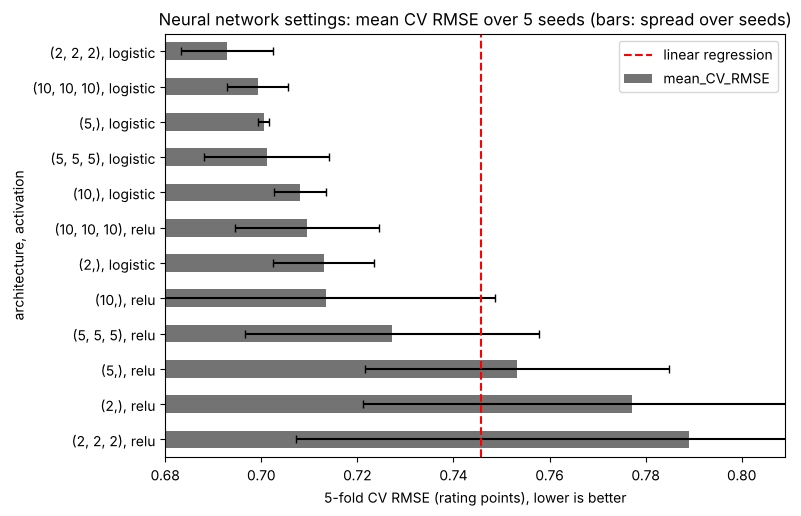

In [17]:
# [AI-assisted] Claude Code, 2026-11-11. Chart of mean CV RMSE by setting, with the spread over seeds as error bars; reviewed and edited by Rowan John.
plot_df = by_setting.reset_index()
plot_df["setting"] = plot_df["architecture"] + ", " + plot_df["activation"]
plot_df = plot_df.sort_values("mean_CV_RMSE", ascending=False)
ax = plot_df.plot.barh(x="setting", y="mean_CV_RMSE", xerr="sd_over_seeds", color="0.45", legend=False, figsize=(8, 5.5), capsize=3)
ax.axvline(summary["Linear regression"]["CV RMSE"], color="red", linestyle="--", label="linear regression")
ax.set_xlim(0.68, max(0.8, plot_df["mean_CV_RMSE"].max() + 0.02))
ax.set_title("Neural network settings: mean CV RMSE over 5 seeds (bars: spread over seeds)")
ax.set_xlabel("5-fold CV RMSE (rating points), lower is better")
ax.set_ylabel("architecture, activation")
ax.legend()
plt.savefig(os.path.join(FIG_DIR, "06_nn_settings_over_seeds.png"), dpi=200, bbox_inches="tight")
plt.show()

**Takeaway: the chosen setting is (2, 2, 2) with logistic activation**, mean CV RMSE 0.693 over the five seeds (spread: sd 0.010, from 0.686 to 0.709). The added (10, 10, 10) logistic network comes second (0.699), so the bigger grid did not change the answer and the winner is not at the edge of the grid.

**This is why one run was not enough.** Left to itself, each seed picks a different winner: seed 1 picks (10, 10, 10) logistic, seed 2 (2, 2, 2) logistic, seed 3 (10, 10, 10) ReLU, and seeds 4 and 5 (10,) ReLU. The gaps between the top settings (0.006 to 0.008) are smaller than the spread one setting shows across seeds (up to 0.013 for logistic). Logistic networks are steadier than ReLU: (5,) logistic varies by only 0.001 across seeds, while every ReLU network varies by 0.015 to 0.082, and (2, 2, 2) ReLU failed to train with at least one seed (worst 0.922, the average).

**Many fits hit the 2,000-step limit.** Over the 5 seeds x 5 folds, (10,) logistic hit it in 25 of 25 fits, (5,) logistic in 24, (10, 10, 10) logistic in 23 and (5, 5, 5) logistic in 16. The chosen (2, 2, 2) logistic hit it in 7 of 25. So the wider logistic networks were still improving when they stopped, and with more steps they might score a little better; keeping the lab's `max_iter=2000` is a deliberate limit, not a sign that they had converged.

## Part 5: Score the test games once per seed

The chosen setting is fitted on all training games with each of the five seeds and scored once on the test games: the same games as task 1's tree and k-NN. Linear regression and the yardstick have no random starting point, so they are scored once.

In [18]:
# [AI-assisted] Claude Code, 2026-11-11. Fit the chosen setting with each seed on the training games, check the fit, and score once on the test games; reviewed and edited by Rowan John.
def test_scores(pred):
    return {"test RMSE": np.sqrt(mean_squared_error(y_test_nonscaled, pred)), "test MAE": mean_absolute_error(y_test_nonscaled, pred),
            "test R2": r2_score(y_test_nonscaled, pred)}

seed_rows, seed_preds = [], {}
for seed in seeds:
    nnet = make_pipeline(MLPRegressor(hidden_layer_sizes=BEST_H, activation=best_act, solver="lbfgs", tol=1e-8, max_iter=MAX_ITER, random_state=seed))
    nnet.fit(X_train_nonscaled, y_train)
    steps = nnet.named_steps["model"].n_iter_
    train_pred = to_ratings(nnet.predict(X_train_nonscaled))
    seed_preds[seed] = to_ratings(nnet.predict(X_test_nonscaled))
    seed_rows.append({"seed": seed, "training steps": steps, "hit max_iter": "yes" if steps >= MAX_ITER else "no",
                      "train RMSE": np.sqrt(mean_squared_error(actual, train_pred)), **test_scores(seed_preds[seed]),
                      "lowest prediction": seed_preds[seed].min(), "highest prediction": seed_preds[seed].max()})
per_seed = pd.DataFrame(seed_rows).set_index("seed")
per_seed.round(3)

,training steps,hit max_iter,train RMSE,test RMSE,test MAE,test R2,lowest prediction,highest prediction
seed,,,,,,,,
1,1742,no,0.684,0.702,0.529,0.426,4.831,8.602
2,1591,no,0.678,0.695,0.526,0.438,5.221,8.847
3,2000,yes,0.684,0.697,0.526,0.435,4.522,8.294
4,1329,no,0.684,0.698,0.527,0.433,4.341,8.191
5,886,no,0.699,0.707,0.535,0.418,5.560,8.102


In [19]:
# [AI-assisted] Claude Code, 2026-11-11. Test scores: network as mean and spread over seeds, next to linear regression and the yardstick; reviewed and edited by Rowan John.
others = {}
for name, model in [("Predict the average (DummyRegressor)", DummyRegressor()), ("Linear regression", LinearRegression())]:
    m = make_pipeline(model).fit(X_train_nonscaled, y_train)
    others[name] = test_scores(to_ratings(m.predict(X_test_nonscaled)))
test_table = pd.DataFrame(others).T
for col in ["test RMSE", "test MAE", "test R2"]:
    test_table.loc[f"Neural network {best_arch} {best_act}, mean of 5 seeds", col] = per_seed[col].mean()
    test_table.loc[f"Neural network {best_arch} {best_act}, sd over 5 seeds", col] = per_seed[col].std()
print(f"test games: {len(y_test_nonscaled):,} (the same as notebook 05's)")
test_table.round(3)

test games: 6,415 (the same as notebook 05's)


,test RMSE,test MAE,test R2
Predict the average (DummyRegressor),0.927,0.728,-0.000
Linear regression,0.748,0.576,0.348
"Neural network (2, 2, 2) logistic, mean of 5 seeds",0.700,0.529,0.430
"Neural network (2, 2, 2) logistic, sd over 5 seeds",0.005,0.004,0.008


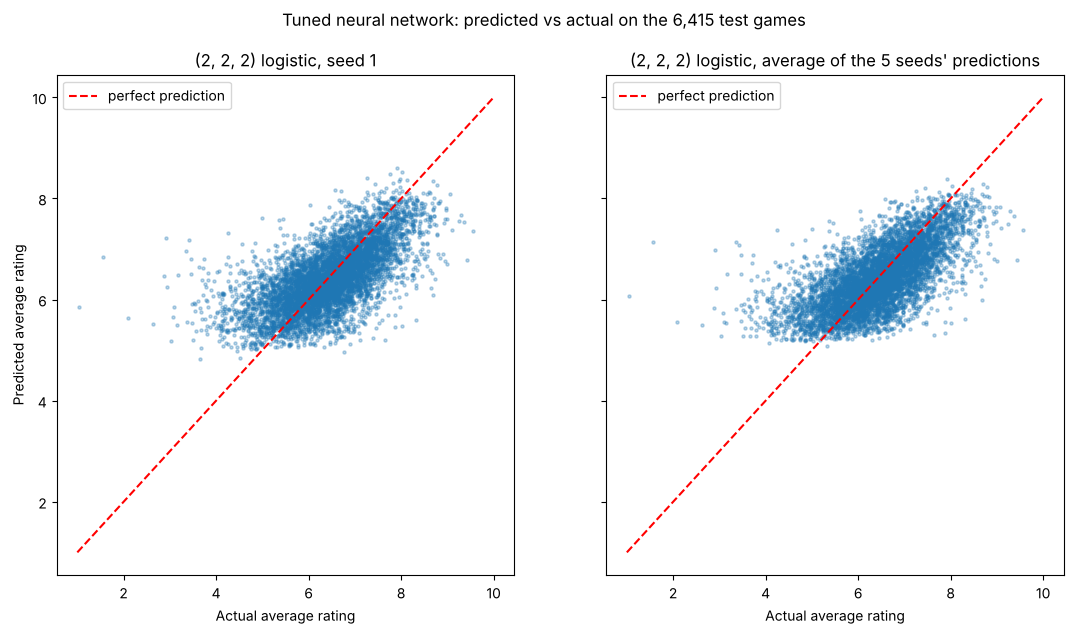

In [20]:
# [AI-assisted] Claude Code, 2026-11-11. Predicted against actual rating, the network with seed 1 as in the lab, with the seed-average prediction alongside; reviewed and edited by Rowan John.
avg_pred = np.mean([seed_preds[s] for s in seeds], axis=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), sharey=True)
for ax, pred, title in [(axes[0], seed_preds[1], "seed 1"), (axes[1], avg_pred, "average of the 5 seeds' predictions")]:
    ax.scatter(y_test_nonscaled, pred, s=5, alpha=0.3)
    ax.plot([1, 10], [1, 10], color="red", linestyle="--", label="perfect prediction")
    ax.set_title(f"{best_arch} {best_act}, {title}")
    ax.set_xlabel("Actual average rating")
    ax.legend()
axes[0].set_ylabel("Predicted average rating")
fig.suptitle(f"Tuned neural network: predicted vs actual on the {len(y_test_nonscaled):,} test games")
plt.savefig(os.path.join(FIG_DIR, "06_nn_predicted_vs_actual.png"), dpi=200, bbox_inches="tight")
plt.show()

**Takeaway:** on the 6,415 test games, the same as task 1's, the (2, 2, 2) logistic network scores **RMSE 0.700 ± 0.005** (mean ± sd over the five seeds; 0.695 to 0.707), **MAE 0.529 ± 0.004** and **R² 0.430 ± 0.008**. It beats linear regression (0.748, 0.576, 0.348) and the yardstick (0.927) with every seed. Test RMSE is close to the CV RMSE (0.693) and to training RMSE (0.678 to 0.699), so the network is not overfitting.

**The final fits trained properly.** Four of the five stopped on their own (886 to 1,742 steps); seed 3 used all 2,000. Unlike the earlier version of this notebook, no final fit got stuck: every training RMSE is close to the CV RMSE. Seed 5 stopped earliest (886 steps) and has the highest training and test RMSE (0.699 and 0.707), but it is still within the spread.

As with every model so far, predictions are pulled towards the middle: they run from about 4.3 to 8.8 while actual ratings run from 1.3 to 9.1. The network under-predicts the best games and over-predicts the worst. Averaging the five seeds' predictions (right-hand chart) does not change that pattern.

## What did not work, and notes

- **The lab's default settings failed.** With `tol=1e-4` and `max_iter=200` no network beat linear regression, and both three-layer networks stopped after 4 steps and predicted the average. Lowering `tol` to `1e-8` fixed it, as in the lab.
- **One seed was not enough.** A first version tuned with `random_state=1` only; re-run on another computer, it picked a different network and gave a different test score. Over five seeds, four different settings each won at least one seed. Choosing by the average over seeds fixed this.
- **A single final fit can get stuck.** In that first version the chosen (5, 5, 5) network's final fit stopped early and scored worse on the test games than in cross-validation. With five seeds, one bad fit can no longer decide the reported score.
- **ReLU was unstable.** It varied far more across seeds than logistic, and (2, 2, 2) ReLU failed to train with at least one seed.
- **Bigger was not better.** (10, 10, 10), added because (5, 5, 5) was the biggest option in the first grid, came second to (2, 2, 2).
- **Many fits ran out of steps.** The wider logistic networks hit `max_iter=2000` in 16 to 25 of 25 fits, so their scores are for networks that had not finished training.

- **Results can still move a little on another computer.** The `lbfgs` solver's arithmetic can differ slightly between machines and library versions, which changes where a long training run ends up. Reporting five seeds' mean and spread is how this notebook handles that: a re-run elsewhere should land inside the spread, not on the same digits.
- Rows, split, inputs and imputer are task 1's (notebook 05, section 13), so the test games are the same 6,415 as task 1's tree and k-NN. Comparing the three is task 10.